In [ ]:
!pip install -q imbalanced-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df = pd.read_csv("creditcard.csv")

In [ ]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
# Step 1: Inspect the dataset

In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (71396, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71396 entries, 0 to 71395
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    71396 non-null  int64  
 1   V1      71396 non-null  float64
 2   V2      71396 non-null  float64
 3   V3      71396 non-null  float64
 4   V4      71396 non-null  float64
 5   V5      71396 non-null  float64
 6   V6      71396 non-null  float64
 7   V7      71396 non-null  float64
 8   V8      71396 non-null  float64
 9   V9      71396 non-null  float64
 10  V10     71396 non-null  float64
 11  V11     71396 non-null  float64
 12  V12     71396 non-null  float64
 13  V13     71396 non-null  float64
 14  V14     71396 n

In [ ]:
display(df.describe().T)

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
Time,71396.0,35055.563561,14520.870592,0.000000,28974.000000,38225.000000,46035.000000,54281.000000
V1,71396.0,-0.250504,1.878010,-56.407510,-1.010292,-0.248095,1.153531,1.960497
V2,71396.0,-0.024291,1.662180,-72.715728,-0.593559,0.072348,0.727542,18.902453
V3,71396.0,0.680177,1.416337,-33.680984,0.193390,0.770235,1.402152,4.226108
V4,71396.0,0.168666,1.374613,-5.172595,-0.725828,0.187351,1.052356,16.715537
V5,71396.0,-0.271040,1.391090,-42.147898,-0.889117,-0.304114,0.267542,34.801666
V6,71396.0,0.099770,1.306664,-26.160506,-0.637894,-0.152017,0.493215,22.529298
V7,71396.0,-0.114766,1.254943,-31.764946,-0.604620,-0.074537,0.420223,36.677268
V8,71396.0,0.056620,1.235873,-73.216718,-0.141800,0.067075,0.346259,20.007208
V9,71396.0,0.015428,1.158743,-9.283925,-0.674023,-0.072527,0.664229,10.392889


Missing values: 5
Duplicate rows: 276


In [ ]:
print(df["Class"].value_counts().sort_index())

Class
0.0    71218
1.0      177
Name: count, dtype: int64


In [ ]:
# Step 2: Analyse class imbalance

In [ ]:
class_counts = df["Class"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "Transaction Type": ["Legitimate", "Fraudulent"],
    "Count": [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ],
    "Percentage": [
        (class_counts.get(0, 0) / len(df)) * 100,
        (class_counts.get(1, 0) / len(df)) * 100
    ]
})

print(class_summary.round(4))

  Transaction Type  Count  Percentage
0       Legitimate  71218     99.7507
1       Fraudulent    177      0.2479


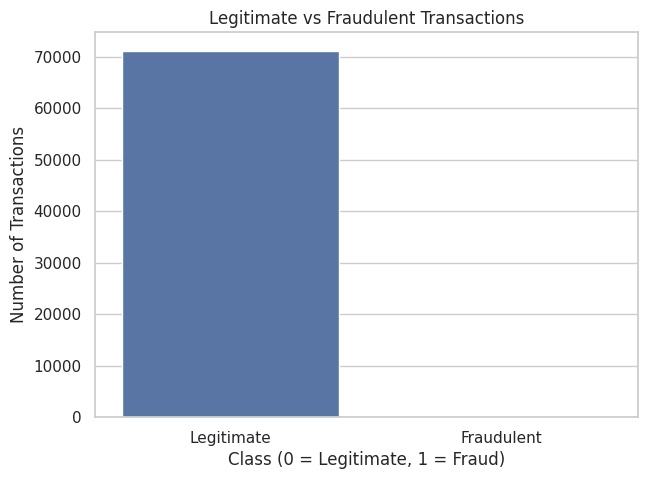

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])
plt.show()

In [ ]:
#### Why Accuracy Is Misleading in Fraud Detection
'''
The credit card fraud dataset is highly imbalanced because fraudulent transactions represent only a very small percentage of all transactions. A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy on the standard dataset while detecting zero fraud cases.

Therefore, accuracy alone is not a reliable measure of fraud detection performance. Precision, recall, F1-score, and ROC-AUC provide more useful information about how well the model identifies fraud and how many legitimate transactions it incorrectly flags. The choice of evaluation metric should reflect the cost of missed fraud and false alarms.
'''

'\nThe credit card fraud dataset is highly imbalanced because fraudulent transactions represent only a very small percentage of all transactions. A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy on the standard dataset while detecting zero fraud cases.\n\nTherefore, accuracy alone is not a reliable measure of fraud detection performance. Precision, recall, F1-score, and ROC-AUC provide more useful information about how well the model identifies fraud and how many legitimate transactions it incorrectly flags. The choice of evaluation metric should reflect the cost of missed fraud and false alarms.\n'

In [ ]:
# Srep 3: Exploratory Data Analysis (EDA)

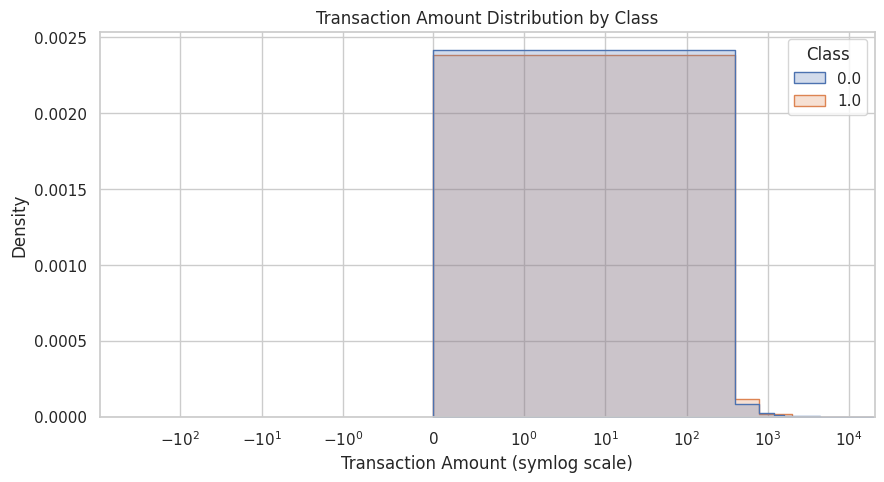

In [ ]:
# Compare transaction amounts
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.xscale("symlog", linthresh=1)
plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount (symlog scale)")
plt.ylabel("Density")
plt.show()

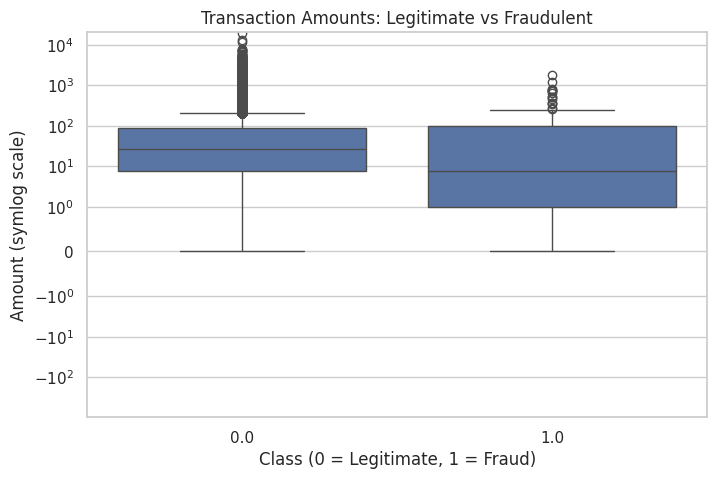

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Class", y="Amount")

plt.yscale("symlog", linthresh=1)
plt.title("Transaction Amounts: Legitimate vs Fraudulent")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Amount (symlog scale)")
plt.show()

In [ ]:
# Compare median amounts
print(df.groupby("Class")["Amount"].describe())

         count       mean         std  min   25%    50%    75%       max
Class                                                                   
0.0    71218.0  97.028781  270.410639  0.0  7.68  26.55  88.50  19656.53
1.0      177.0  95.719153  219.167165  0.0  1.00   7.61  99.99   1809.68


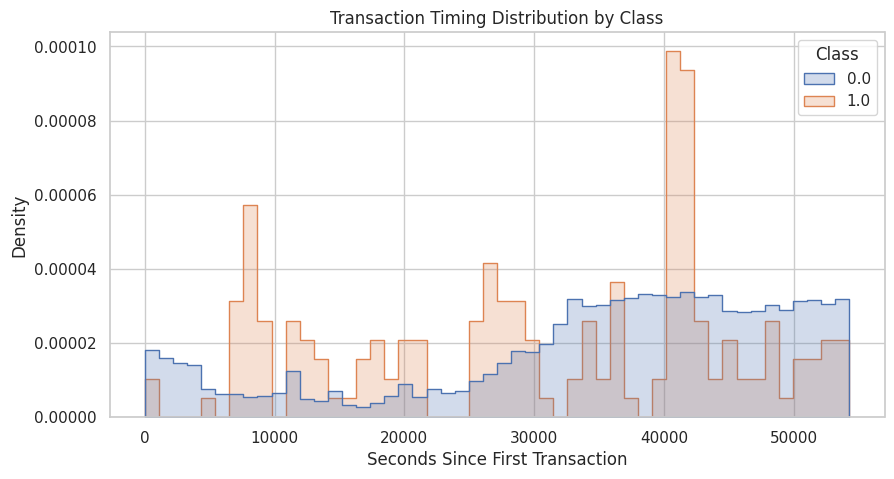

In [ ]:
# Analyse transaction timing
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Timing Distribution by Class")
plt.xlabel("Seconds Since First Transaction")
plt.ylabel("Density")
plt.show()

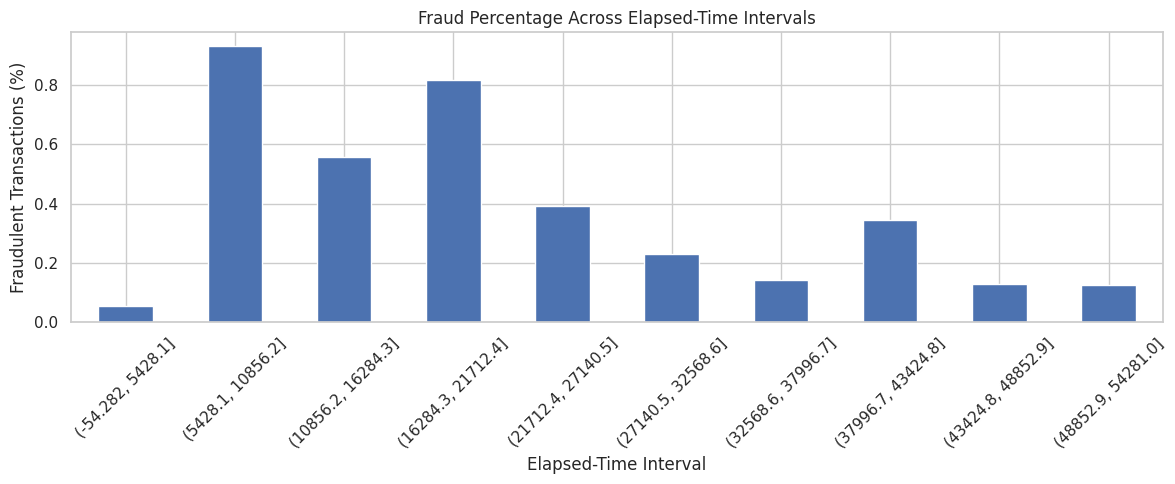

In [ ]:
time_df = df.copy()

time_df["Time_Bin"] = pd.cut(
    time_df["Time"],
    bins=10,
    include_lowest=True
)

fraud_by_time = time_df.groupby(
    "Time_Bin",
    observed=False
)["Class"].mean() * 100

fraud_by_time.plot(kind="bar", figsize=(12, 5))

plt.title("Fraud Percentage Across Elapsed-Time Intervals")
plt.xlabel("Elapsed-Time Interval")
plt.ylabel("Fraudulent Transactions (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Step 4Prepare features and target

In [ ]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (71396, 30)
Target shape: (71396,)


In [ ]:
print("Missing values in y:", y.isnull().sum())
print("\nMissing values in each column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values in y: 1

Missing values in each column:
V26       1
V27       1
V28       1
Amount    1
Class     1
dtype: int64


In [ ]:
# Remove rows where the target Class is missing
df = df.dropna(subset=["Class"]).copy()

# Ensure target labels are valid
print("Class values:", df["Class"].unique())

# Recreate features and target
X = df.drop(columns=["Class"])
y = df["Class"]

print("Missing values in target:", y.isnull().sum())
print("Target distribution:")
print(y.value_counts())

Class values: [0. 1.]
Missing values in target: 0
Target distribution:
Class
0.0    71218
1.0      177
Name: count, dtype: int64


In [ ]:
print(df["Class"].value_counts(dropna=False))

Class
0.0    71218
1.0      177
Name: count, dtype: int64


In [ ]:
print("Missing values in X:", X.isnull().sum().sum())

Missing values in X: 0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training set: (57116, 30)
Testing set: (14279, 30)

Training class distribution:
Class
0.0    56974
1.0      142
Name: count, dtype: int64

Testing class distribution:
Class
0.0    14244
1.0       35
Name: count, dtype: int64


In [ ]:
# Step 5: Handle class imbalance using SMOTE

In [ ]:
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
Class
0.0    56974
1.0      142
Name: count, dtype: int64


In [ ]:
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train,
    y_train
)

print("After SMOTE:")
print(y_train_resampled.value_counts())

After SMOTE:
Class
0.0    56974
1.0    56974
Name: count, dtype: int64


In [ ]:
# Step 6: Train Model 1 — Logistic Regression

In [ ]:
logistic_model = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
# Step 7: Train Model 2 — Random Forest

In [ ]:
rf_model = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
# Step 8: Evaluate both models

In [ ]:
# Create an evaluation function
def evaluate_model(name, y_true, y_pred, y_prob):
    print("=" * 55)
    print(name)
    print("=" * 55)

    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(
        y_true, y_pred, zero_division=0
    ), 4))
    print("Recall:", round(recall_score(
        y_true, y_pred, zero_division=0
    ), 4))
    print("F1-score:", round(f1_score(
        y_true, y_pred, zero_division=0
    ), 4))
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.show()

Logistic Regression
Accuracy: 0.9784
Precision: 0.0947
Recall: 0.9143
F1-score: 0.1716
ROC-AUC: 0.9831

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     14244
       Fraud       0.09      0.91      0.17        35

    accuracy                           0.98     14279
   macro avg       0.55      0.95      0.58     14279
weighted avg       1.00      0.98      0.99     14279



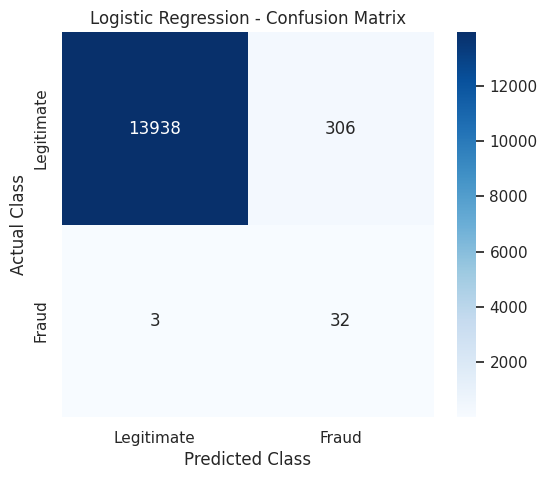

In [ ]:
# Evaluate Logistic Regression
evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_pred,
    logistic_prob
)

Random Forest
Accuracy: 0.9994
Precision: 0.8649
Recall: 0.9143
F1-score: 0.8889
ROC-AUC: 0.9676

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     14244
       Fraud       0.86      0.91      0.89        35

    accuracy                           1.00     14279
   macro avg       0.93      0.96      0.94     14279
weighted avg       1.00      1.00      1.00     14279



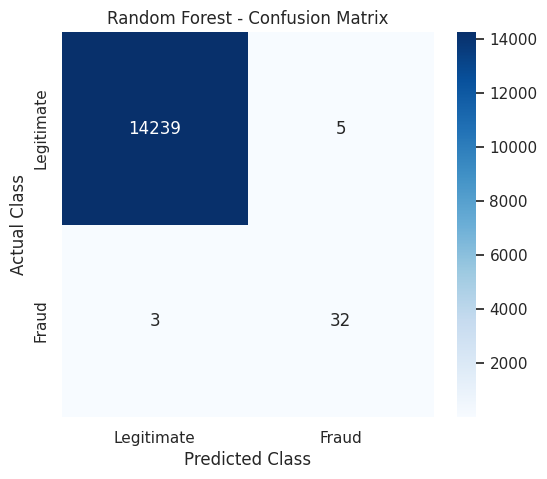

In [ ]:
# Evaluate Random Forest
evaluate_model(
    "Random Forest",
    y_test,
    rf_pred,
    rf_prob
)

In [ ]:
# Step 9: Plot the AUC-ROC curve

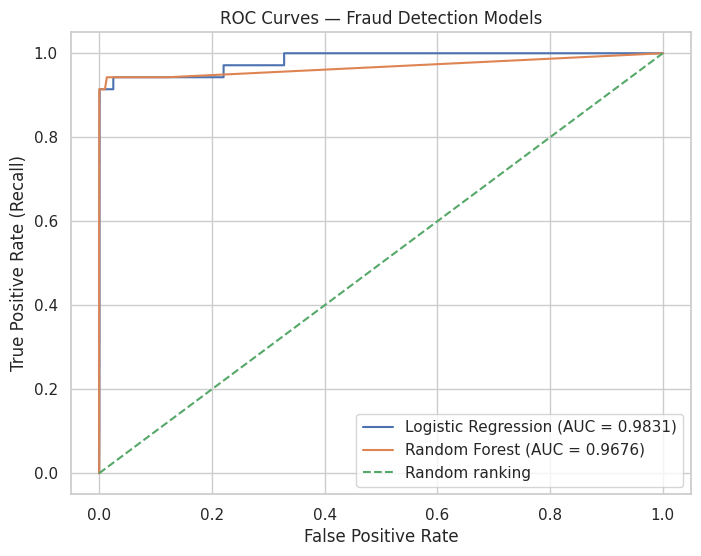

In [ ]:
fpr_log, tpr_log, _ = roc_curve(y_test, logistic_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

auc_log = roc_auc_score(y_test, logistic_prob)
auc_rf = roc_auc_score(y_test, rf_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log, tpr_log,
    label=f"Logistic Regression (AUC = {auc_log:.4f})"
)

plt.plot(
    fpr_rf, tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")

plt.title("ROC Curves — Fraud Detection Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.show()

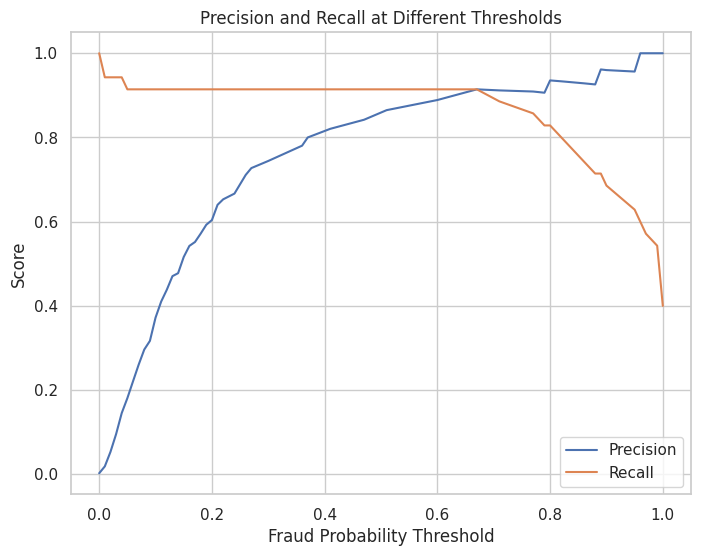

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test, rf_prob
)

plt.figure(figsize=(8, 6))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")

plt.title("Precision and Recall at Different Thresholds")
plt.xlabel("Fraud Probability Threshold")
plt.ylabel("Score")
plt.legend()
plt.show()

In [ ]:
# Step 11: Feature importance analysis

In [ ]:
rf_classifier = rf_model.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_classifier.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

   Feature  Importance
14     V14    0.188407
10     V10    0.114017
12     V12    0.093837
17     V17    0.091063
3       V3    0.080494
16     V16    0.065980
4       V4    0.058930
11     V11    0.055992
2       V2    0.051972
9       V9    0.026172
29  Amount    0.025744
21     V21    0.017531
7       V7    0.012341
18     V18    0.011470
5       V5    0.010709


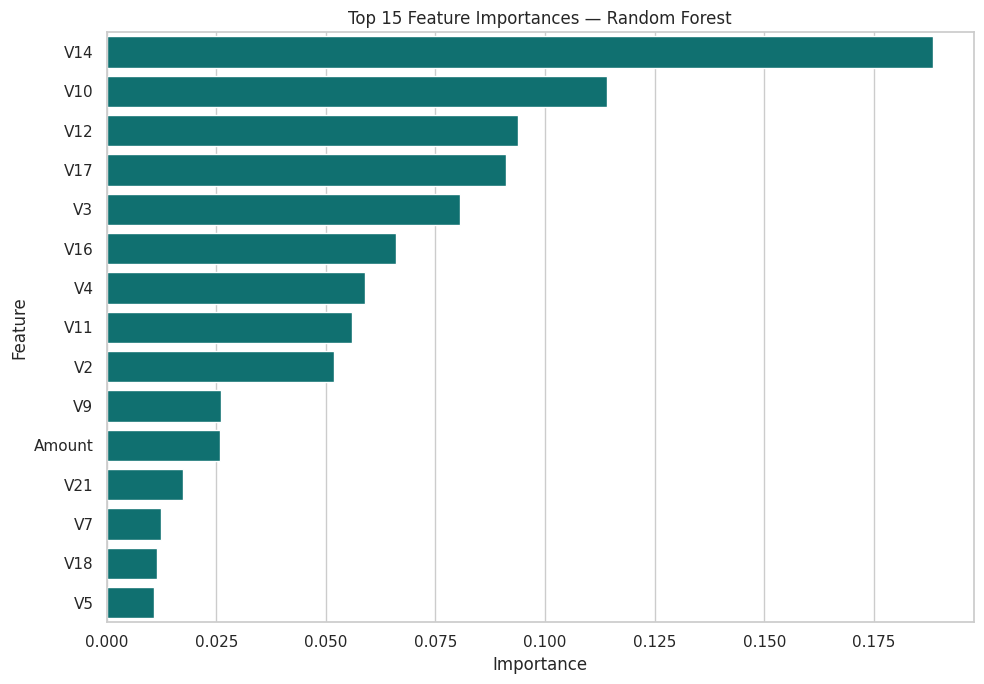

In [ ]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="teal"
)

plt.title("Top 15 Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
# Step 12: Compare the two models

In [ ]:
model_predictions = {
    "Logistic Regression": (logistic_pred, logistic_prob),
    "Random Forest": (rf_pred, rf_prob)
}

results = []

for name, (pred, prob) in model_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression    0.9784     0.0947  0.9143    0.1716   0.9831
1        Random Forest    0.9994     0.8649  0.9143    0.8889   0.9676


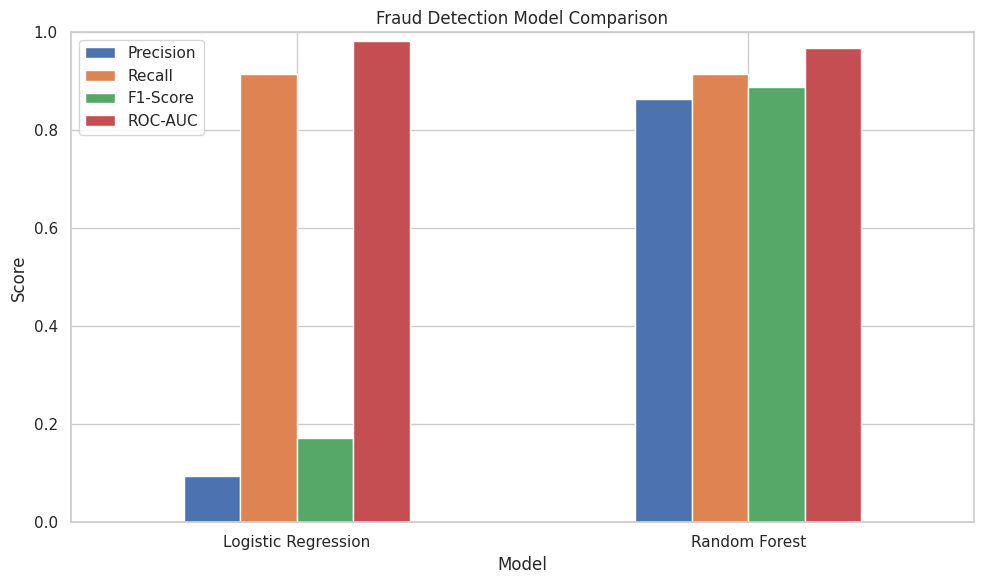

In [ ]:
results_df.to_csv("fraud_model_comparison.csv", index=False)

metrics = results_df.set_index("Model")[
    ["Precision", "Recall", "F1-Score", "ROC-AUC"]
]

metrics.plot(kind="bar", figsize=(10, 6), ylim=(0, 1))

plt.title("Fraud Detection Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# step 13: Scalability — handling 1 million transactions per hour

In [ ]:
# ## Conclusion
'''
The Fraud Detection project developed a machine learning pipeline to identify fraudulent credit card transactions in a highly imbalanced dataset. Exploratory Data Analysis was used to examine transaction amounts, elapsed-time patterns, and the distribution of fraud cases. SMOTE was applied only to the training data to address class imbalance.

Logistic Regression and Random Forest were trained and evaluated using precision, recall, F1-score, ROC-AUC, and confusion matrices. Based on the test results, **[insert selected model]** was the preferred candidate because it achieved **[insert relevant metric values]** and provided a suitable balance between detecting fraudulent transactions and limiting false alerts.

The project demonstrates why accuracy alone is insufficient for fraud detection. Before deployment, the selected model would require threshold tuning, validation on more representative data, latency and scalability testing, and ongoing monitoring for changing fraud patterns.
'''

'\nThe Fraud Detection project developed a machine learning pipeline to identify fraudulent credit card transactions in a highly imbalanced dataset. Exploratory Data Analysis was used to examine transaction amounts, elapsed-time patterns, and the distribution of fraud cases. SMOTE was applied only to the training data to address class imbalance.\n\nLogistic Regression and Random Forest were trained and evaluated using precision, recall, F1-score, ROC-AUC, and confusion matrices. Based on the test results, **[insert selected model]** was the preferred candidate because it achieved **[insert relevant metric values]** and provided a suitable balance between detecting fraudulent transactions and limiting false alerts.\n\nThe project demonstrates why accuracy alone is insufficient for fraud detection. Before deployment, the selected model would require threshold tuning, validation on more representative data, latency and scalability testing, and ongoing monitoring for changing fraud pattern